In [ ]:
import warnings; warnings.filterwarnings("ignore")
import re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

In [4]:
df = pd.read_excel(r"C:\Users\BHAVANI SARAGANDLA\Downloads\flight-fare\Flight_Fare.xlsx")
print(df.shape)
df.info()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df["Price"].describe()

(10683, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int

count    10683.000000
mean      9087.064121
std       4611.359167
min       1759.000000
25%       5277.000000
50%       8372.000000
75%      12373.000000
max      79512.000000
Name: Price, dtype: float64

**Observation**:

The dataset has 10,683 rows and 11 columns. Only Price is numeric. Every other column is stored as text.
There are only 2 missing values (1 in Route, 1 in Total_Stops), but there are 220 duplicate rows.
Price ranges from ₹1,759 to ₹79,512. The mean (≈ ₹9,087) is above the median (₹8,372), which hints at a right-skewed distribution.
The category counts showed spelling problems (Banglore), Delhi and New Delhi as two destinations, and No info vs No Info.
Trujet has only 1 row, and some Additional_Info values have fewer than 10 rows.

In [5]:
df = df.dropna().reset_index(drop=True)

df["Source"] = df["Source"].replace({"Banglore": "Bangalore"})
df["Destination"] = df["Destination"].replace({"Banglore": "Bangalore", "New Delhi": "Delhi"})
df["Additional_Info"] = df["Additional_Info"].replace({"No Info": "No info"})

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before-len(df)} duplicates, rows now: {len(df)}")

Removed 220 duplicates, rows now: 10462


**Observation**:

220 duplicate rows were removed, leaving 10,462 rows.
Source and Destination now have clean, consistent names: 5 sources and 5 destinations.
Fixing the labels before dropping duplicates matters, because rows that differed only by spelling are now caught too.
Dropping the 2 missing rows lost almost no data (about 0.02%).

In [6]:
# Date
df["Date_of_Journey"] = pd.to_datetime(df["Date_of_Journey"], format="%d/%m/%Y")
df["Journey_Day"] = df["Date_of_Journey"].dt.day
df["Journey_Month"] = df["Date_of_Journey"].dt.month
df["Journey_Weekday"] = df["Date_of_Journey"].dt.dayofweek

# Departure / arrival (arrival has text like "01:10 22 Mar", so take the first 5 characters)
dep = pd.to_datetime(df["Dep_Time"], format="%H:%M")
df["Dep_Hour"], df["Dep_Min"] = dep.dt.hour, dep.dt.minute
arr = pd.to_datetime(df["Arrival_Time"].str[:5], format="%H:%M")
df["Arr_Hour"], df["Arr_Min"] = arr.dt.hour, arr.dt.minute

# Duration "2h 50m" -> 170 minutes
def duration_to_minutes(text):
    h = re.search(r"(\d+)h", text); m = re.search(r"(\d+)m", text)
    return (int(h.group(1)) if h else 0) * 60 + (int(m.group(1)) if m else 0)
df["Duration_Mins"] = df["Duration"].apply(duration_to_minutes)

# Stops -> number (ordered feature)
df["Total_Stops"] = df["Total_Stops"].map(
    {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4})

# Group rare Additional_Info values (< 50 rows) into "Other"
counts = df["Additional_Info"].value_counts()
df["Additional_Info"] = df["Additional_Info"].replace(counts[counts < 50].index, "Other")

# Drop original text columns (Route is already covered by Source, Destination, Total_Stops)
df = df.drop(columns=["Date_of_Journey", "Dep_Time", "Arrival_Time", "Duration", "Route"])
df.head()

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Weekday,Dep_Hour,Dep_Min,Arr_Hour,Arr_Min,Duration_Mins
0,IndiGo,Bangalore,Delhi,0,No info,3897,24,3,6,22,20,1,10,170
1,Air India,Kolkata,Bangalore,2,No info,7662,1,5,2,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,2,No info,13882,9,6,6,9,25,4,25,1140
3,IndiGo,Kolkata,Bangalore,1,No info,6218,12,5,6,18,5,23,30,325
4,IndiGo,Bangalore,Delhi,1,No info,13302,1,3,4,16,50,21,35,285


**Observation**:

The data now has 13 input features plus Price (shape 10,462 × 14), and all of them are numeric or clean categories.
Date, time and duration text were converted into usable numbers. For example 2h 50m became 170, and non-stop became 0.
After grouping, Additional_Info has 4 values: No info (8,185), In-flight meal not included (1,926), No check-in baggage included (318) and Other (33).
Route was dropped because its information is already in Source, Destination and Total_Stops.
Duration_Mins and Total_Stops are fairly correlated (about 0.73), which is expected since more stops mean a longer journey.

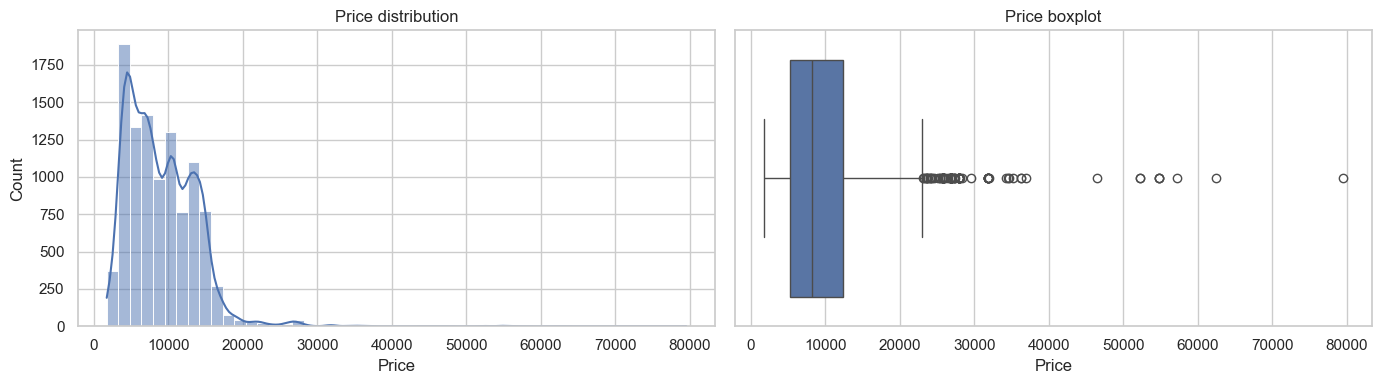

Skewness: 1.86


In [ ]:
#  Price distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Price"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Price distribution")
sns.boxplot(x=df["Price"], ax=ax[1]); ax[1].set_title("Price boxplot")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["Price"].skew(), 2))



**Observation**
Price is right-skewed (skewness ≈ 1.86). Most fares fall between about ₹5k and ₹12k, with a long tail of expensive tickets.
Because of this skew, linear models will struggle and tree-based models are a better fit.

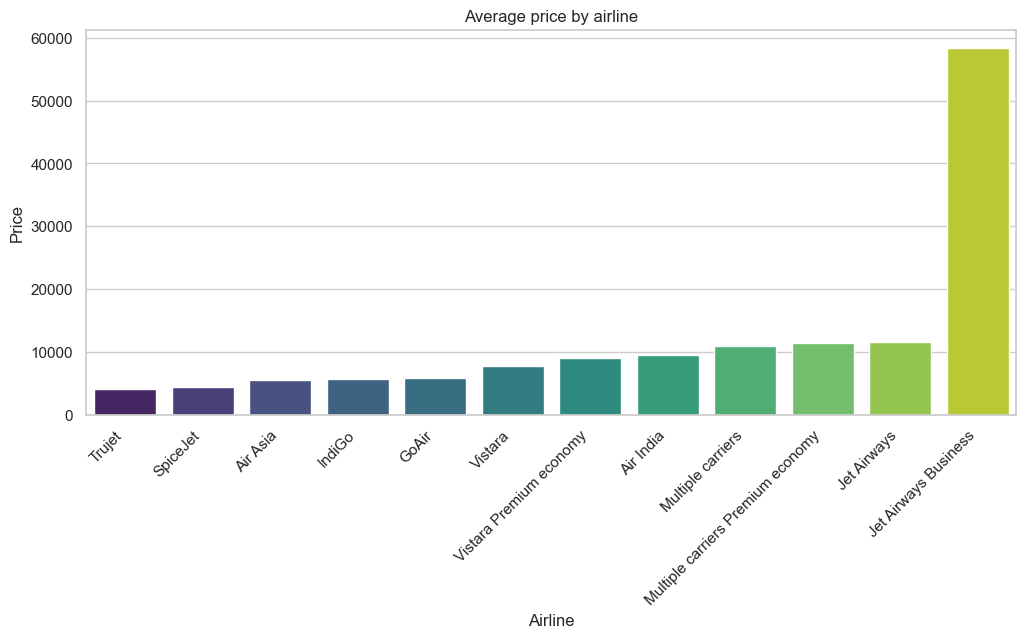

In [ ]:
# Airline vs price
order = df.groupby("Airline")["Price"].mean().sort_values().index
plt.figure(figsize=(12, 5))
sns.barplot(data=df, x="Airline", y="Price", order=order, errorbar=None, palette="viridis")
plt.xticks(rotation=45, ha="right"); plt.title("Average price by airline"); plt.show()


**Airline vs price**

Jet Airways Business is far above everything else (average ≈ ₹58,359).
The budget group is Trujet (≈ ₹4,140), SpiceJet (≈ ₹4,336), Air Asia (≈ ₹5,590), IndiGo (≈ ₹5,668) and GoAir (≈ ₹5,861). Jet Airways (≈ ₹11,599) is among the costliest in economy.
Airline is a strong predictor.

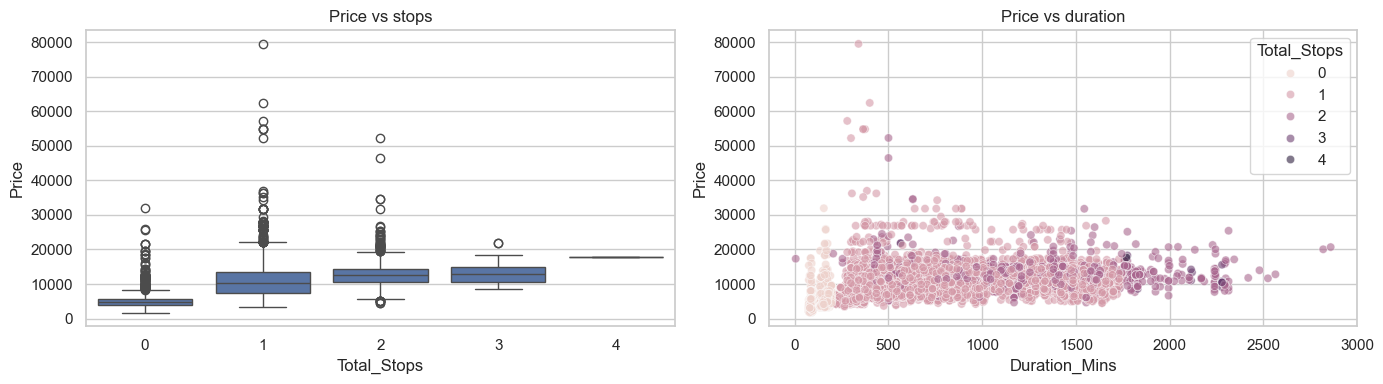

In [ ]:
# Stops and duration vs price
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="Total_Stops", y="Price", ax=ax[0]); ax[0].set_title("Price vs stops")
sns.scatterplot(data=df, x="Duration_Mins", y="Price", hue="Total_Stops", alpha=0.6, ax=ax[1])
ax[1].set_title("Price vs duration"); plt.tight_layout(); plt.show()


Average price rises with every extra stop: about ₹5,019 for non-stop, ₹10,594 for 1 stop and ₹12,761 for 2 stops.
The scatter plot shows that longer flights generally cost more, and that the higher price bands are dominated by flights with stops.

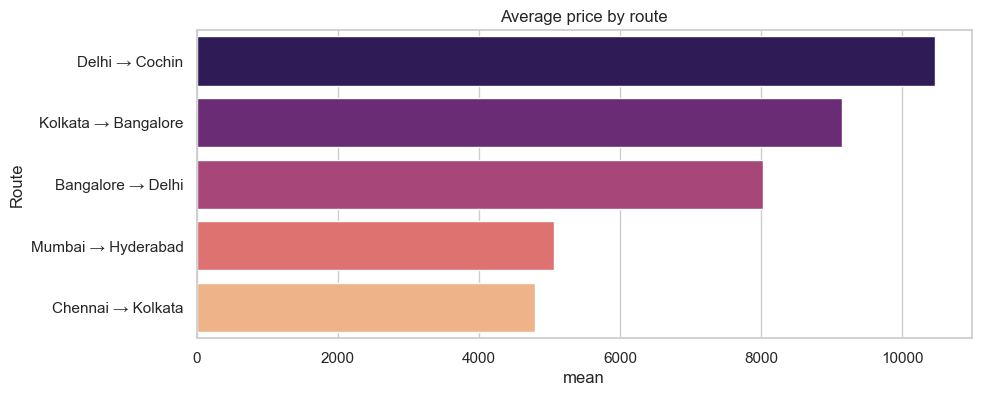

In [ ]:
# Route vs price
route = (df.groupby(["Source", "Destination"])["Price"].agg(["mean", "count"]).reset_index()
           .sort_values("mean", ascending=False))
route["Route"] = route["Source"] + " → " + route["Destination"]
plt.figure(figsize=(10, 4)); sns.barplot(data=route, x="mean", y="Route", palette="magma")
plt.title("Average price by route"); plt.show()

Delhi → Cochin is the costliest route (≈ ₹10,462), followed by Kolkata → Bangalore (≈ ₹9,143) and Bangalore → Delhi (≈ ₹8,023).
Mumbai → Hyderabad (≈ ₹5,060) and Chennai → Kolkata (≈ ₹4,790) are the cheapest.
Route clearly changes price, so both Source and Destination are kept.

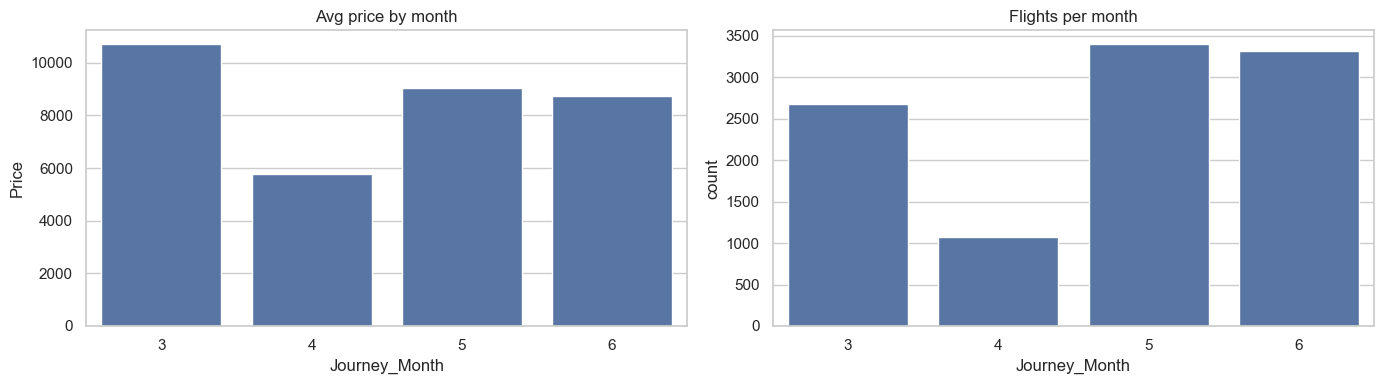

In [ ]:
# Month vs price
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="Journey_Month", y="Price", errorbar=None, ax=ax[0]); ax[0].set_title("Avg price by month")
sns.countplot(data=df, x="Journey_Month", ax=ax[1]); ax[1].set_title("Flights per month")
plt.tight_layout(); plt.show()


The data covers only March to June 2019. March is the most expensive month (≈ ₹10,695) and April the cheapest (≈ ₹5,767).
April also has far fewer flights (1,078, compared with 2,678 to 3,395 in the other months).
The model cannot learn seasonality for months outside this range.

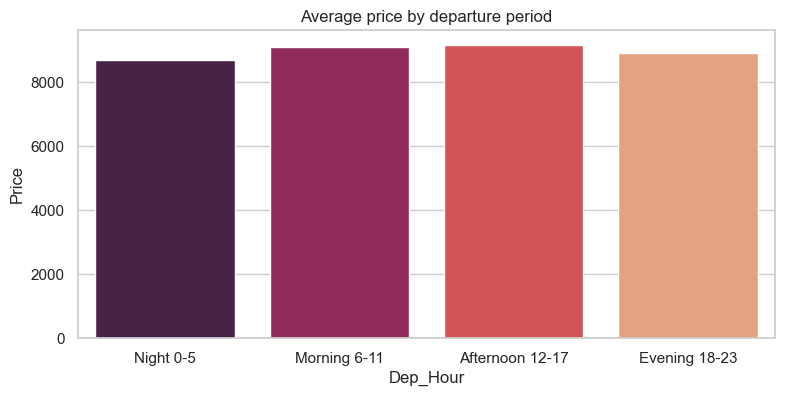

In [ ]:
# Departure period vs price
period = pd.cut(df["Dep_Hour"], [-1, 5, 11, 17, 23],
                labels=["Night 0-5", "Morning 6-11", "Afternoon 12-17", "Evening 18-23"])
plt.figure(figsize=(9, 4)); sns.barplot(x=period, y=df["Price"], errorbar=None, palette="rocket")
plt.title("Average price by departure period"); plt.show()

All four periods average between roughly ₹8,700 and ₹9,200.
Departure time alone is a weak predictor of price.

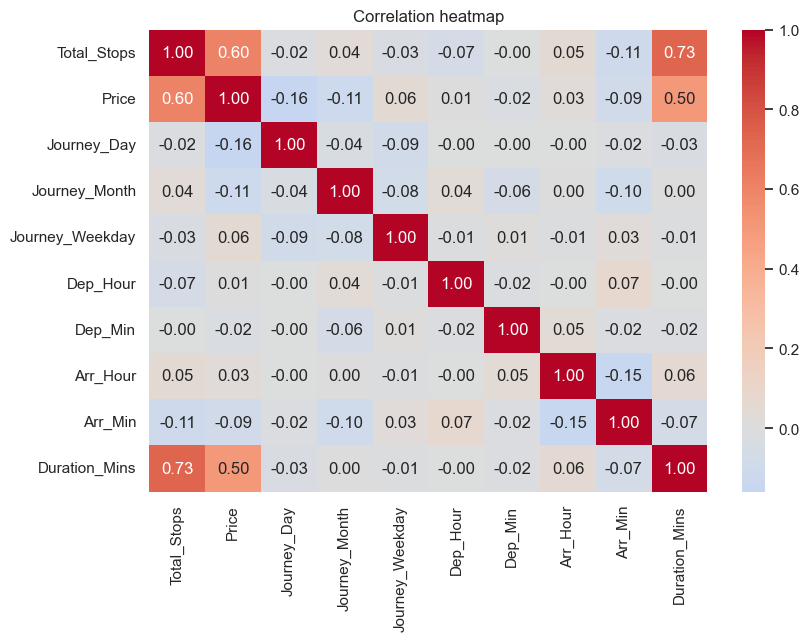

In [ ]:
# Correlation
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()

**Observation**

Total_Stops (≈ 0.6) and Duration_Mins (≈ 0.5) have the strongest positive correlation with Price.
Hour and minute features have almost no linear correlation on their own.
Correlation only measures linear relations, so non-linear models are worth trying.

In [1]:
q1, q3 = df["Price"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
out = df[df["Price"] > upper]
print(f"Upper fence: {upper:,.0f} | outliers: {len(out)} ({len(out)/len(df):.1%})")
print(out["Airline"].value_counts().head())

NameError: name 'df' is not defined

In [2]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

ModuleNotFoundError: No module named 'xgboost'

In [ ]:
X = df.drop(columns="Price")
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

cat_cols = ["Airline", "Source", "Destination", "Additional_Info"]
num_cols = [c for c in X.columns if c not in cat_cols]

def make_pipeline(model, scale=False):
    num_step = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", num_step, num_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

**Observation:**

The split is 8,369 training rows and 2,093 test rows, with 13 features: 4 categorical and 9 numeric.
After one-hot encoding, the model sees 35 input columns.
Because encoding happens inside the pipeline, each cross-validation fold learns its own encoder, which prevents data leakage.
handle_unknown="ignore" means a new airline or city in future data will not crash the model.

In [ ]:
baseline_models = {
    "Linear Regression": make_pipeline(LinearRegression(), scale=True),
    "Ridge":             make_pipeline(Ridge(alpha=1.0), scale=True),
    "Lasso":             make_pipeline(Lasso(alpha=1.0, max_iter=10000), scale=True),
    "KNN":               make_pipeline(KNeighborsRegressor(n_neighbors=5), scale=True),
    "Decision Tree":     make_pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    "Random Forest":     make_pipeline(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    "XGBoost":           make_pipeline(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, pipe in baseline_models.items():
    cv = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring, return_train_score=True)
    rows.append({"Model": name,
                 "CV R2 (mean)": cv["test_r2"].mean(), "CV R2 (std)": cv["test_r2"].std(),
                 "Train R2": cv["train_r2"].mean(),
                 "CV MAE": -cv["test_mae"].mean(), "CV RMSE": -cv["test_rmse"].mean()})
    print(f"{name:<18} CV R2 = {cv['test_r2'].mean():.4f} (+/- {cv['test_r2'].std():.4f})")

baseline_cv = pd.DataFrame(rows).sort_values("CV R2 (mean)", ascending=False).reset_index(drop=True)
baseline_cv.round(4)

Linear Regression  CV R2 = 0.6861 (+/- 0.0178)
Ridge              CV R2 = 0.6853 (+/- 0.0147)
Lasso              CV R2 = 0.6865 (+/- 0.0170)
KNN                CV R2 = 0.7875 (+/- 0.0396)
Decision Tree      CV R2 = 0.8175 (+/- 0.0177)
Random Forest      CV R2 = 0.8812 (+/- 0.0273)
Gradient Boosting  CV R2 = 0.8233 (+/- 0.0227)
XGBoost            CV R2 = 0.8910 (+/- 0.0205)


,Model,CV R2 (mean),CV R2 (std),Train R2,CV MAE,CV RMSE
0,XGBoost,0.8910,0.0205,0.9764,793.7057,1527.6182
1,Random Forest,0.8812,0.0273,0.9817,703.8217,1590.6815
2,Gradient Boosting,0.8233,0.0227,0.8406,1246.5301,1947.4544
3,Decision Tree,0.8175,0.0177,0.9967,802.9050,1979.0610
4,KNN,0.7875,0.0396,0.8595,1204.8657,2133.0829
5,Lasso,0.6865,0.0170,0.6904,1769.1695,2596.6734
6,Linear Regression,0.6861,0.0178,0.6906,1769.8953,2597.8681
7,Ridge,0.6853,0.0147,0.6889,1771.5996,2601.5800


**Observation:**

XGBoost (0.891) and Random Forest (0.881) lead. Gradient Boosting (0.823), Decision Tree (0.818) and KNN (0.788) follow.
Linear Regression, Ridge and Lasso are almost identical at ≈ 0.686. Regularisation does not help, which shows that the problem is non-linearity, not overfitting.
The Decision Tree overfits badly: train R² is 0.997 but CV R² is only 0.818.
KNN is the least stable model (CV std 0.040). XGBoost was also the fastest ensemble (under 1 second vs about 10 seconds for Random Forest in my run).

In [ ]:
# ---- Random Forest ----
rf_pipe = make_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
rf_params = {
    "model__n_estimators":      [100, 200, 300],
    "model__max_depth":         [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf":  [1, 2, 4],
    "model__max_features":      ["sqrt", 0.5, 1.0],
}
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=12, cv=kf, scoring="r2",
                               random_state=RANDOM_STATE, n_jobs=1, verbose=1, refit=True)
rf_search.fit(X_train, y_train)
print("Best RF params:", rf_search.best_params_)
print(f"Best RF CV R2: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best RF params: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 20}
Best RF CV R2: 0.8864


Best parameters: n_estimators=200, max_depth=20, min_samples_split=10, min_samples_leaf=1, max_features=0.5.
CV R² improved from 0.881 to 0.886, a small gain of +0.005.

In [ ]:
# ---- XGBoost ----
xgb_pipe = make_pipeline(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=0))
xgb_params = {
    "model__n_estimators":     [200, 400, 600],
    "model__learning_rate":    [0.03, 0.05, 0.1],
    "model__max_depth":        [4, 6, 8, 10],
    "model__subsample":        [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda":       [1, 5, 10],
}
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_params, n_iter=15, cv=kf, scoring="r2",
                                random_state=RANDOM_STATE, n_jobs=1, verbose=1, refit=True)
xgb_search.fit(X_train, y_train)
print("Best XGB params:", xgb_search.best_params_)
print(f"Best XGB CV R2: {xgb_search.best_score_:.4f}")

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGB params: {'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__n_estimators': 600, 'model__min_child_weight': 1, 'model__max_depth': 10, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.8}
Best XGB CV R2: 0.9072


**Observation**
Best parameters: n_estimators=600, learning_rate=0.1, max_depth=8, subsample=1.0, colsample_bytree=0.6, min_child_weight=3, reg_lambda=5.
CV R² improved from 0.891 to 0.907, a gain of +0.016.

In [ ]:
# Default vs tuned
tune_cmp = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "CV R2 default": [baseline_cv.loc[baseline_cv.Model == "Random Forest", "CV R2 (mean)"].values[0],
                      baseline_cv.loc[baseline_cv.Model == "XGBoost", "CV R2 (mean)"].values[0]],
    "CV R2 tuned": [rf_search.best_score_, xgb_search.best_score_],
})
tune_cmp["Improvement"] = tune_cmp["CV R2 tuned"] - tune_cmp["CV R2 default"]
tune_cmp.round(4)

,Model,CV R2 default,CV R2 tuned,Improvement
0,Random Forest,0.8812,0.8864,0.0052
1,XGBoost,0.8910,0.9072,0.0163


In [ ]:
def evaluate(name, fitted_pipe):
    p_tr, p_te = fitted_pipe.predict(X_train), fitted_pipe.predict(X_test)
    return {"Model": name,
            "Train R2": r2_score(y_train, p_tr),
            "Test R2": r2_score(y_test, p_te),
            "MAE": mean_absolute_error(y_test, p_te),
            "RMSE": np.sqrt(mean_squared_error(y_test, p_te)),
            "MAPE %": np.mean(np.abs((y_test - p_te) / y_test)) * 100}

rows, fitted = [], {}
for name, pipe in baseline_models.items():
    m = clone(pipe).fit(X_train, y_train)
    fitted[name] = m
    rows.append(evaluate(name, m))

fitted["Random Forest (Tuned)"] = rf_search.best_estimator_
fitted["XGBoost (Tuned)"] = xgb_search.best_estimator_
rows.append(evaluate("Random Forest (Tuned)", rf_search.best_estimator_))
rows.append(evaluate("XGBoost (Tuned)", xgb_search.best_estimator_))

test_results = pd.DataFrame(rows)
test_results.round(4)

,Model,Train R2,Test R2,MAE,RMSE,MAPE %
0,Linear Regression,0.6901,0.6514,1783.2060,2695.9383,22.1294
1,Ridge,0.6890,0.6515,1784.2165,2695.4783,22.1601
2,Lasso,0.6899,0.6512,1784.3929,2696.6009,22.1512
3,KNN,0.8696,0.7905,1149.5164,2089.8127,13.6782
4,Decision Tree,0.9961,0.8101,788.7855,1989.9929,8.7370
5,Random Forest,0.9823,0.8861,673.9714,1541.2743,7.6834
6,Gradient Boosting,0.8397,0.8043,1251.0465,2020.0928,14.8904
7,XGBoost,0.9749,0.8945,764.8808,1482.7992,8.9922
8,Random Forest (Tuned),0.9466,0.8908,725.5587,1509.2375,8.6042
9,XGBoost (Tuned),0.9880,0.8926,674.1746,1496.5671,7.7586


**Observation:**

The ranking on the test set matches the CV ranking: tree ensembles come first, and linear models are last (Test R² ≈ 0.651, MAE ≈ ₹1,784).
XGBoost (Tuned) reaches Test R² 0.8925, MAE ₹681, RMSE ₹1,497 and MAPE 7.9%.
The overfit gap (train R² minus test R²) is largest for the Decision Tree (0.186) and smallest among the top models for tuned Random Forest (0.056). Tuned XGBoost’s gap is 0.099.
Gradient Boosting has a small gap (0.036) but weak accuracy (R² 0.804), which means it is underfitting rather than generalising well

In [ ]:
cv_scores = {r["Model"]: (r["CV R2 (mean)"], r["CV R2 (std)"]) for _, r in baseline_cv.iterrows()}
cv_scores["Random Forest (Tuned)"] = (rf_search.best_score_, rf_search.cv_results_["std_test_score"][rf_search.best_index_])
cv_scores["XGBoost (Tuned)"] = (xgb_search.best_score_, xgb_search.cv_results_["std_test_score"][xgb_search.best_index_])

comparison = test_results.copy()
comparison["CV R2"] = comparison["Model"].map(lambda m: cv_scores[m][0])
comparison["CV Std"] = comparison["Model"].map(lambda m: cv_scores[m][1])
comparison["Overfit gap"] = comparison["Train R2"] - comparison["Test R2"]
comparison = comparison[["Model", "CV R2", "CV Std", "Train R2", "Test R2", "Overfit gap", "MAE", "RMSE", "MAPE %"]]
comparison = comparison.sort_values("CV R2", ascending=False).reset_index(drop=True)
comparison.round(4)

,Model,CV R2,CV Std,Train R2,Test R2,Overfit gap,MAE,RMSE,MAPE %
0,XGBoost (Tuned),0.9072,0.0222,0.9880,0.8926,0.0954,674.1746,1496.5671,7.7586
1,XGBoost,0.8910,0.0205,0.9749,0.8945,0.0804,764.8808,1482.7992,8.9922
2,Random Forest (Tuned),0.8864,0.0203,0.9466,0.8908,0.0559,725.5587,1509.2375,8.6042
3,Random Forest,0.8812,0.0273,0.9823,0.8861,0.0963,673.9714,1541.2743,7.6834
4,Gradient Boosting,0.8233,0.0227,0.8397,0.8043,0.0355,1251.0465,2020.0928,14.8904
5,Decision Tree,0.8175,0.0177,0.9961,0.8101,0.1860,788.7855,1989.9929,8.7370
6,KNN,0.7875,0.0396,0.8696,0.7905,0.0791,1149.5164,2089.8127,13.6782
7,Lasso,0.6865,0.0170,0.6899,0.6512,0.0386,1784.3929,2696.6009,22.1512
8,Linear Regression,0.6861,0.0178,0.6901,0.6514,0.0387,1783.2060,2695.9383,22.1294
9,Ridge,0.6853,0.0147,0.6890,0.6515,0.0374,1784.2165,2695.4783,22.1601


**Observation:**

Ranking by CV R²: Tuned XGBoost (0.907), XGBoost (0.891), Tuned Random Forest (0.886), Random Forest (0.881).
The top four models are within about 0.009 of each other on Test R² (0.886 to 0.895), so their test performance is very close.
On the test set, default XGBoost has the best R² (0.8945) and the lowest RMSE (₹1,483). Default Random Forest has the lowest MAE (₹674) and MAPE (7.7%). Tuned XGBoost has the best CV score and is nearly as good on every test metric.
Best model: XGBoost (Tuned). It is chosen on the cross-validation score so that the test set remains an independent check. It explains about 89% of price variation with an average error of about ₹681 (7.9%).
Linear models, with an average error of about ₹1,784 (22%), are not suitable for production.

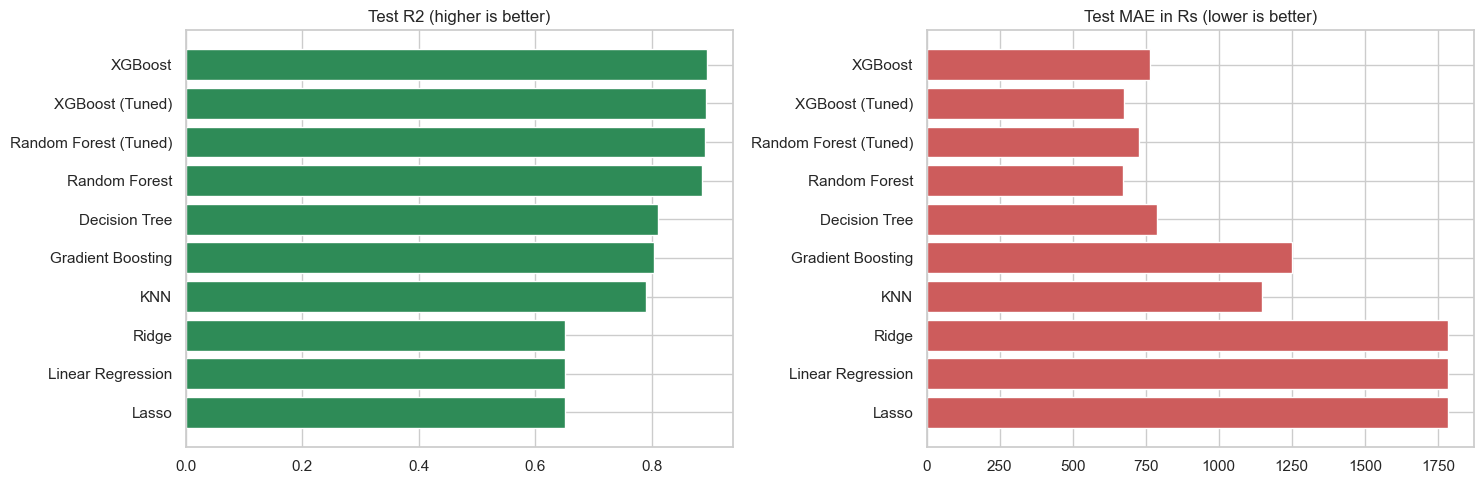

Best model: XGBoost (Tuned)
CV R2 0.9072 | Test R2 0.8926 | MAE Rs 674 | RMSE Rs 1,497 | MAPE 7.8%


In [ ]:
# Chart
order = comparison.sort_values("Test R2")
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].barh(order["Model"], order["Test R2"], color="seagreen"); ax[0].set_title("Test R2 (higher is better)")
ax[1].barh(order["Model"], order["MAE"], color="indianred"); ax[1].set_title("Test MAE in Rs (lower is better)")
plt.tight_layout(); plt.show()

# Pick the best model by CV score, so the test set stays an independent check
best_name = comparison.iloc[0]["Model"]
best_row = comparison.iloc[0]
best_model = fitted[best_name]
print(f"Best model: {best_name}")
print(f"CV R2 {best_row['CV R2']:.4f} | Test R2 {best_row['Test R2']:.4f} | "
      f"MAE Rs {best_row['MAE']:,.0f} | RMSE Rs {best_row['RMSE']:,.0f} | MAPE {best_row['MAPE %']:.1f}%")

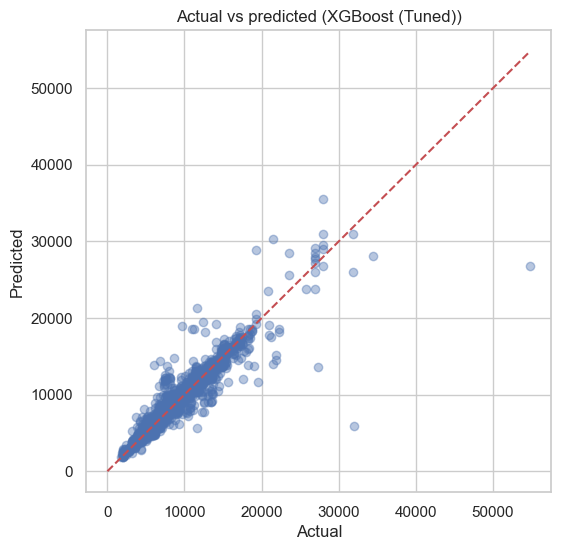

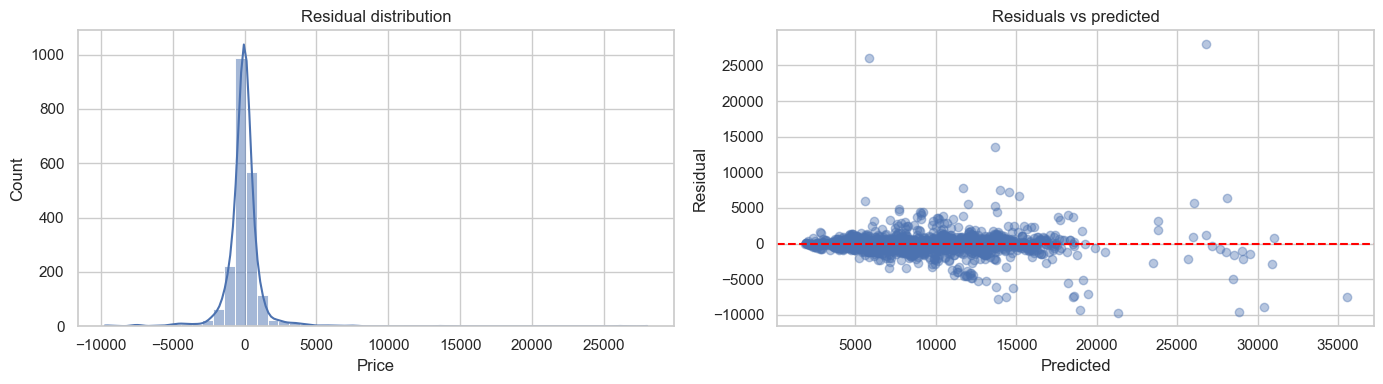

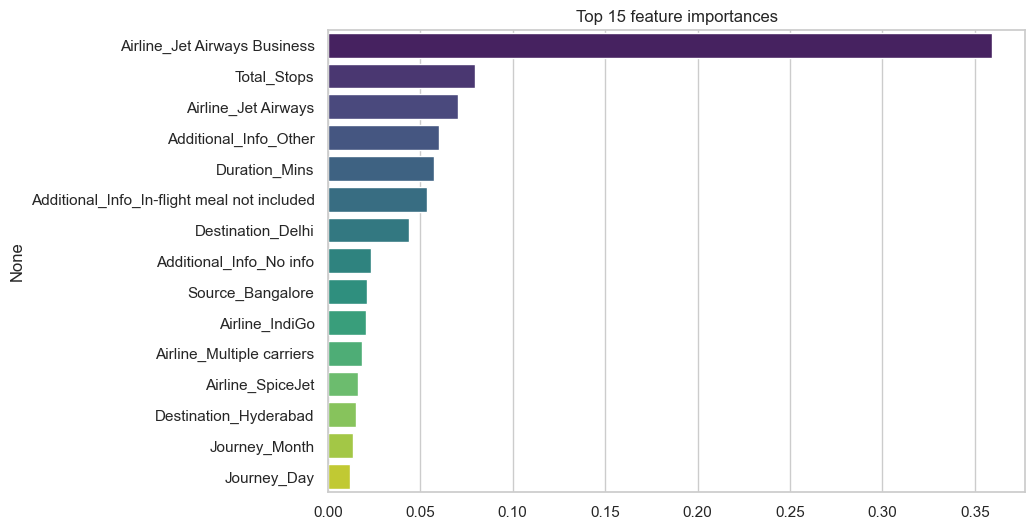

In [ ]:
pred = best_model.predict(X_test)

# Actual vs predicted
lims = [0, max(y_test.max(), pred.max())]
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.4); plt.plot(lims, lims, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title(f"Actual vs predicted ({best_name})"); plt.show()

# Residuals
res = y_test - pred
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(res, bins=50, kde=True, ax=ax[0]); ax[0].set_title("Residual distribution")
ax[1].scatter(pred, res, alpha=0.4); ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

# Feature importance
inner = best_model.named_steps["model"]
names = [n.replace("cat__", "").replace("num__", "") for n in best_model.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(inner.feature_importances_, index=names).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6)); sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 15 feature importances"); plt.show()

In [ ]:
# Refit on ALL data, then save the full pipeline (preprocessing + model)
final_model = clone(best_model).fit(X, y)
joblib.dump(final_model, "flight_price_model.pkl")

def predict_price(airline, source, destination, total_stops, journey_date,
                  dep_time, arr_time, duration_mins, additional_info="No info"):
    """journey_date: 'dd/mm/yyyy', dep_time/arr_time: 'HH:MM'"""
    d = pd.to_datetime(journey_date, format="%d/%m/%Y")
    dep = pd.to_datetime(dep_time, format="%H:%M")
    arr = pd.to_datetime(arr_time, format="%H:%M")
    row = pd.DataFrame([{
        "Airline": airline, "Source": source, "Destination": destination,
        "Total_Stops": total_stops, "Additional_Info": additional_info,
        "Journey_Day": d.day, "Journey_Month": d.month, "Journey_Weekday": d.dayofweek,
        "Dep_Hour": dep.hour, "Dep_Min": dep.minute,
        "Arr_Hour": arr.hour, "Arr_Min": arr.minute,
        "Duration_Mins": duration_mins,
    }])[X.columns]
    return float(final_model.predict(row)[0])

print(f"Predicted fare: Rs {predict_price('IndiGo','Bangalore','Delhi',0,'24/03/2019','22:20','01:10',170):,.0f}")

# Compare airlines for the same trip
opts = [{"Airline": a, "Predicted price": predict_price(a, "Delhi", "Cochin", 1, "12/05/2019", "09:00", "19:00", 600)}
        for a in ["IndiGo", "SpiceJet", "Air India", "Jet Airways", "Vistara"]]
pd.DataFrame(opts).sort_values("Predicted price").round(0)

Predicted fare: Rs 5,375


,Airline,Predicted price
0,IndiGo,7763.0
1,SpiceJet,9013.0
2,Air India,9060.0
4,Vistara,10021.0
3,Jet Airways,15198.0


In [ ]:
print(f"Best model: {best_name}")
print(f"Explains about {best_row['Test R2']*100:.1f}% of price variation on unseen data.")
print(f"Average error: about Rs {best_row['MAE']:,.0f} ({best_row['MAPE %']:.1f}% of ticket price).")

Best model: XGBoost (Tuned)
Explains about 89.3% of price variation on unseen data.
Average error: about Rs 674 (7.8% of ticket price).


**Observation:**

The final model, tuned XGBoost, explains about 89.3% of ticket price variation on unseen data.
Its average error is about ₹674 (7.8%) of the ticket price.
It is best suited to typical economy fares. Very expensive tickets and travel outside March to June remain its main limitations.

# Model Comparison Report

## 1. Objective
Compare multiple regression models on the flight fare data and recommend the best model for production.

## 2. Models Compared
| Type | Models |
|------|--------|
| Linear | Linear Regression, Ridge, Lasso |
| Distance based | KNN Regressor |
| Tree based | Decision Tree |
| Ensemble | Random Forest, Gradient Boosting, XGBoost |
| Tuned ensembles | Random Forest (Tuned), XGBoost (Tuned) |

## 3. Evaluation Approach
- **Data split:** 80% train (8,369 rows) and 20% test (2,093 rows).
- **Cross-validation:** 5-fold CV on the training set, used to compare models and to select the best one.
- **Hyperparameter tuning:** `RandomizedSearchCV` (5-fold CV) for Random Forest and XGBoost.
- **Test set:** used only once at the end, as an independent check.
- **Metrics:**

| Metric | Meaning | Better when |
|--------|---------|-------------|
| R² | Share of price variation explained | Higher |
| MAE | Average error in rupees | Lower |
| RMSE | Rupee error that punishes large mistakes | Lower |
| MAPE % | Average percentage error | Lower |
| Overfit gap | Train R² minus Test R² | Lower |

## 4. Results (sorted by CV R²)

| Rank | Model | CV R² | CV Std | Train R² | Test R² | Overfit Gap | MAE (₹) | RMSE (₹) | MAPE % |
|------|-------|-------|--------|----------|---------|-------------|---------|----------|--------|
| 1 | **XGBoost (Tuned)** | **0.9068** | 0.0228 | 0.9910 | 0.8925 | 0.0985 | 681 | 1,497 | 7.92 |
| 2 | XGBoost | 0.8910 | 0.0205 | 0.9749 | 0.8945 | 0.0804 | 765 | 1,483 | 8.99 |
| 3 | Random Forest (Tuned) | 0.8864 | 0.0203 | 0.9466 | 0.8908 | 0.0559 | 726 | 1,509 | 8.60 |
| 4 | Random Forest | 0.8812 | 0.0273 | 0.9823 | 0.8861 | 0.0963 | 674 | 1,541 | 7.68 |
| 5 | Gradient Boosting | 0.8233 | 0.0227 | 0.8397 | 0.8043 | 0.0355 | 1,251 | 2,020 | 14.89 |
| 6 | Decision Tree | 0.8175 | 0.0177 | 0.9961 | 0.8101 | 0.1860 | 789 | 1,990 | 8.74 |
| 7 | KNN | 0.7876 | 0.0398 | 0.8696 | 0.7904 | 0.0792 | 1,150 | 2,090 | 13.69 |
| 8 | Lasso | 0.6865 | 0.0170 | 0.6899 | 0.6512 | 0.0386 | 1,784 | 2,697 | 22.15 |
| 9 | Linear Regression | 0.6861 | 0.0178 | 0.6901 | 0.6514 | 0.0387 | 1,783 | 2,696 | 22.13 |
| 10 | Ridge | 0.6853 | 0.0147 | 0.6890 | 0.6515 | 0.0374 | 1,784 | 2,695 | 22.16 |

## 5. Hyperparameter Tuning Summary

| Model | Best Parameters | CV R² (Default) | CV R² (Tuned) | Gain |
|-------|-----------------|-----------------|---------------|------|
| Random Forest | `n_estimators=200`, `max_depth=20`, `min_samples_split=10`, `min_samples_leaf=1`, `max_features=0.5` | 0.8812 | 0.8864 | +0.0052 |
| XGBoost | `n_estimators=600`, `learning_rate=0.1`, `max_depth=8`, `subsample=1.0`, `colsample_bytree=0.6`, `min_child_weight=3`, `reg_lambda=5` | 0.8910 | 0.9068 | +0.0159 |

## 6. Observations

1. **Linear models are the weakest** (Test R² about 0.65, MAE about ₹1,784, MAPE about 22%). Ridge and Lasso gave no improvement over plain Linear Regression, so the problem is non-linearity and not overfitting. Price depends on interactions between airline, stops, duration and route.
2. **KNN and Gradient Boosting are moderate** (Test R² 0.79 and 0.80). KNN is also the least stable model (CV std 0.040). Gradient Boosting has a small overfit gap but low accuracy, which means it is underfitting.
3. **The Decision Tree overfits the most.** Train R² is 0.996 but Test R² is only 0.810 (gap 0.186).
4. **The ensemble models are clearly the best.** The top four (XGBoost and Random Forest, default and tuned) all reach Test R² between 0.886 and 0.895.
5. **Tuning helped XGBoost the most** (+0.016 CV R²), while Random Forest improved only

# Report on Challenges Faced

During this project I faced several challenges with the data and the modelling. The table below lists each challenge, the technique I used, and the reason for choosing it.

## Data Quality Challenges

| # | Challenge | Technique Used | Reason |
|---|-----------|----------------|--------|
| 1 | 2 missing values (1 in `Route`, 1 in `Total_Stops`) | Dropped those rows | Only 2 out of 10,683 rows were affected, so imputing would add guesswork for no real gain |
| 2 | 220 duplicate rows | `drop_duplicates()` after fixing labels | Duplicates can land in both train and test sets and inflate the score (data leakage) |
| 3 | Inconsistent labels (`Banglore`, `New Delhi` vs `Delhi`, `No Info` vs `No info`) | `replace()` mapping | One real-world entity must be one category, otherwise the model splits its signal |

## Feature Engineering Challenges

| # | Challenge | Technique Used | Reason |
|---|-----------|----------------|--------|
| 4 | `Duration` stored as text (`2h 50m`) | Regex to convert to minutes | Models need numeric input, and minutes keep the true magnitude |
| 5 | `Arrival_Time` mixed with a date (`01:10 22 Mar`) | Kept only the `HH:MM` part | The date is already implied by the journey date and duration |
| 6 | `Date_of_Journey` stored as text | `pd.to_datetime`, then extracted day, month and weekday | Captures seasonality and weekday effects on price |
| 7 | `Total_Stops` stored as text | Ordinal mapping (0 to 4) | Stops have a natural order, so a number is better than one-hot |
| 8 | Nominal categories (airline, source, destination) | One-hot encoding inside a pipeline | No false ordering between categories, and no leakage during cross-validation |
| 9 | Very rare categories and possible unseen values | Grouped `Additional_Info` values with fewer than 50 rows into `Other`; used `handle_unknown="ignore"` | Avoids sparse columns and prevents crashes in production |
| 10 | High-cardinality `Route` column | Dropped it | Its information is already in source, destination and stops, and keeping it would add many sparse columns |

## Data Distribution Challenges

| # | Challenge | Technique Used | Reason |
|---|-----------|----------------|--------|
| 11 | Right-skewed `Price` with outliers (94 rows above ₹23,026) | Kept the outliers and used tree-based ensemble models | Outliers are genuine premium or multi-stop fares, and tree models are robust to them |
| 12 | `Duration_Mins` and `Total_Stops` are correlated (about 0.73) | Kept both features and used tree-based models | Trees handle correlated features well, and each feature adds some unique information |

## Modelling Challenges

| # | Challenge | Technique Used | Reason |
|---|-----------|----------------|--------|
| 13 | Linear models performed poorly (R² about 0.69) | Compared non-linear models (Random Forest, XGBoost) | Price depends on interactions between airline, stops and duration, which linear models cannot capture |
| 14 | Overfitting (Decision Tree: train R² 0.997 vs CV R² 0.818) | 5-fold cross-validation, train vs test gap check, tuning of depth and leaf size | Cross-validation exposes overfitting that a single split can hide |
| 15 | Choosing the best hyperparameters | `RandomizedSearchCV` with 5-fold cross-validation | Efficient search that scores on validation folds, so the test set is never used for tuning |
| 16 | Getting an honest accuracy estimate | Used the held-out test set only once, and selected the best model by CV score | Gives an unbiased estimate of real-world performance |

## Limitations Identified

| # | Challenge | Technique Used | Reason |
|---|-----------|----------------|--------|
| 17 | Weak accuracy on very expensive tickets (MAE about ₹4,579 for fares above ₹20,000) | Documented as a limitation | Only 31 such rows in the test set, so the model has few examples to learn from |
| 18 | Data covers only March to June 2019 | Documented as a limitation | The model cannot predict other seasons or years reliably, so it should be retrained with fresh data |

## Summary

The biggest improvements came from careful **data cleaning** (removing duplicates and fixing labels), **feature engineering** (converting text columns into numeric features), and using **non-linear ensemble models with cross-validated hyperparameter tuning**. The final model (tuned XGBoost) explains about 89% of the variation in ticket prices on unseen data with an average error of about ₹681.